In [1]:
!pip install kaggle

In [2]:
from google.colab import files

files.upload()

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"tejomahikorrapati","key":"f615f8acd4c0f44b027f1c1b44d1a54b"}'}

In [3]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

In [4]:
!kaggle datasets download -d kmader/skin-cancer-mnist-ham10000

Dataset URL: https://www.kaggle.com/datasets/kmader/skin-cancer-mnist-ham10000
License(s): CC-BY-NC-SA-4.0
100% 5.20G/5.20G [00:33<00:00, 167MB/s]



In [5]:
import os
from zipfile import ZipFile
import glob

zip_files = glob.glob("/content/skin-cancer-mnist-ham10000.zip")

with ZipFile(zip_files[0], "r") as zip_ref:
    zip_ref.extractall("/content/skin_lesion_dataset")

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [6]:
for root, dirs, files in os.walk("/content/skin_lesion_dataset"):
    print(root, "->", len(files), "files")

/content/skin_lesion_dataset -> 5 files
/content/skin_lesion_dataset/HAM10000_images_part_2 -> 5015 files
/content/skin_lesion_dataset/ham10000_images_part_1 -> 5000 files
/content/skin_lesion_dataset/HAM10000_images_part_1 -> 5000 files
/content/skin_lesion_dataset/ham10000_images_part_2 -> 5015 files


In [7]:
dataset_path = "/content/skin_lesion_dataset"

for root, dirs, files in os.walk(dataset_path):
    level = root.replace(dataset_path, "").count(os.sep)
    indent = " " * 4 * level

    print(f"{indent}{os.path.basename(root)}/")

    for file in files[:5]:
        print(f"{indent}    {file}")

    if level >= 2:
        dirs[:] = []

skin_lesion_dataset/
    hmnist_8_8_L.csv
    HAM10000_metadata.csv
    hmnist_28_28_L.csv
    hmnist_8_8_RGB.csv
    hmnist_28_28_RGB.csv
    HAM10000_images_part_2/
        ISIC_0029969.jpg
        ISIC_0031302.jpg
        ISIC_0033553.jpg
        ISIC_0030374.jpg
        ISIC_0033565.jpg
    ham10000_images_part_1/
        ISIC_0025645.jpg
        ISIC_0024972.jpg
        ISIC_0025419.jpg
        ISIC_0027312.jpg
        ISIC_0026927.jpg
    HAM10000_images_part_1/
        ISIC_0025645.jpg
        ISIC_0024972.jpg
        ISIC_0025419.jpg
        ISIC_0027312.jpg
        ISIC_0026927.jpg
    ham10000_images_part_2/
        ISIC_0029969.jpg
        ISIC_0031302.jpg
        ISIC_0033553.jpg
        ISIC_0030374.jpg
        ISIC_0033565.jpg


Check the dataset files


In [8]:
for root, dirs, files in os.walk(dataset_path):
    for file in files:
        if file.endswith((".csv", ".jpg", ".jpeg", ".png")):
            print(os.path.join(root, file))
            if file.endswith((".jpg", ".jpeg", ".png")):
                break
    if any(f.endswith(".csv") for f in files):
        print("CSV found in:", root)

/content/skin_lesion_dataset/hmnist_8_8_L.csv
/content/skin_lesion_dataset/HAM10000_metadata.csv
/content/skin_lesion_dataset/hmnist_28_28_L.csv
/content/skin_lesion_dataset/hmnist_8_8_RGB.csv
/content/skin_lesion_dataset/hmnist_28_28_RGB.csv
CSV found in: /content/skin_lesion_dataset
/content/skin_lesion_dataset/HAM10000_images_part_2/ISIC_0029969.jpg
/content/skin_lesion_dataset/ham10000_images_part_1/ISIC_0025645.jpg
/content/skin_lesion_dataset/HAM10000_images_part_1/ISIC_0025645.jpg
/content/skin_lesion_dataset/ham10000_images_part_2/ISIC_0029969.jpg


Import Libraries and inspect the metadataa

In [9]:
import pandas as pd
from glob import glob
from glob import glob
import os
import matplotlib.pyplot as plt
from PIL import Image
import os
from glob import glob
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit
from sklearn.model_selection import GroupShuffleSplit
import tensorflow as tf
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, Model
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

In [10]:
dataset_path = "/content/skin_lesion_dataset"
metadata_path = os.path.join(dataset_path, "HAM10000_metadata.csv")

In [11]:
# Load metadata
df = pd.read_csv(metadata_path)

In [12]:
print("Dataset shape:", df.shape)

Dataset shape: (10015, 7)


In [13]:
print("\nFirst 5 rows:")
display(df.head())


First 5 rows:


,lesion_id,image_id,dx,dx_type,age,sex,localization
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear


In [14]:
print("\nColumn names:")
print(df.columns.tolist())


Column names:
['lesion_id', 'image_id', 'dx', 'dx_type', 'age', 'sex', 'localization']


In [15]:
print("\nMissing values:")
print(df.isnull().sum())


Missing values:
lesion_id        0
image_id         0
dx               0
dx_type          0
age             57
sex              0
localization     0
dtype: int64


Check the number of images in each class

In [16]:
print("Images per diagnosis class:")
print(df["dx"].value_counts())

print("\nNumber of unique image IDs:")
print(df["image_id"].nunique())

Images per diagnosis class:
dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64

Number of unique image IDs:
10015


Verify that the image files exist

In [17]:
image_paths = (
    glob(dataset_path + "/HAM10000_images_part_1/*.jpg")
    + glob(dataset_path + "/ham10000_images_part_1/*.jpg")
    + glob(dataset_path + "/HAM10000_images_part_2/*.jpg")
    + glob(dataset_path + "/ham10000_images_part_2/*.jpg")
)

print("Total image files found:", len(image_paths))
print("Example image:", image_paths[0] if image_paths else "No images found")

Total image files found: 20030
Example image: /content/skin_lesion_dataset/HAM10000_images_part_1/ISIC_0025645.jpg


Step 6: Check the diagnosis distribution

In [18]:
print("Dataset shape:", df.shape)

print("\nImages per diagnosis class:")
print(df["dx"].value_counts())

print("\nUnique image IDs:", df["image_id"].nunique())

Dataset shape: (10015, 7)

Images per diagnosis class:
dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64

Unique image IDs: 10015


Step 7: Count the image files


In [19]:
dataset_path = "/content/skin_lesion_dataset"

image_paths = (
    glob(os.path.join(dataset_path, "HAM10000_images_part_1", "*.jpg"))
    + glob(os.path.join(dataset_path, "ham10000_images_part_1", "*.jpg"))
    + glob(os.path.join(dataset_path, "HAM10000_images_part_2", "*.jpg"))
    + glob(os.path.join(dataset_path, "ham10000_images_part_2", "*.jpg"))
)

print("Total image files found:", len(image_paths))

Total image files found: 20030


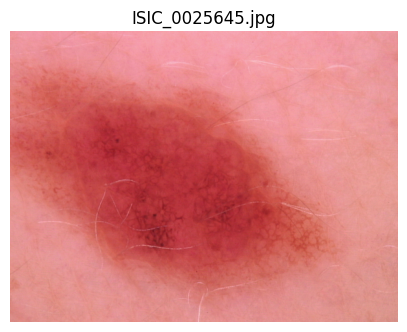

In [20]:
if image_paths:
    img = Image.open(image_paths[0])

    plt.figure(figsize=(5, 5))
    plt.imshow(img)
    plt.title(os.path.basename(image_paths[0]))
    plt.axis("off")
    plt.show()
else:
    print("No images found. Check the image folder paths.")

Step 9: Match image files with their labels

In [21]:
dataset_path = "/content/skin_lesion_dataset"

In [22]:
# Find images in both folders
image_paths = (
    glob(os.path.join(dataset_path, "HAM10000_images_part_1", "*.jpg"))
    + glob(os.path.join(dataset_path, "ham10000_images_part_1", "*.jpg"))
    + glob(os.path.join(dataset_path, "HAM10000_images_part_2", "*.jpg"))
    + glob(os.path.join(dataset_path, "ham10000_images_part_2", "*.jpg"))
)

In [23]:
# Map each image ID to its file path
image_map = {
    os.path.splitext(os.path.basename(path))[0]: path
    for path in image_paths
}

In [24]:
# Connect metadata to image files
df["image_path"] = df["image_id"].map(image_map)

print("Metadata records:", len(df))
print("Image files found:", len(image_paths))
print("Matched images:", df["image_path"].notna().sum())
print("Unmatched records:", df["image_path"].isna().sum())

display(df[["image_id", "dx", "image_path"]].head())

Metadata records: 10015
Image files found: 20030
Matched images: 10015
Unmatched records: 0


,image_id,dx,image_path
0,ISIC_0027419,bkl,/content/skin_lesion_dataset/ham10000_images_p...
1,ISIC_0025030,bkl,/content/skin_lesion_dataset/ham10000_images_p...
2,ISIC_0026769,bkl,/content/skin_lesion_dataset/ham10000_images_p...
3,ISIC_0025661,bkl,/content/skin_lesion_dataset/ham10000_images_p...
4,ISIC_0031633,bkl,/content/skin_lesion_dataset/ham10000_images_p...


Step 10: Verify the matching

In [25]:
print(df["image_path"].isna().sum() == 0)

True


Step 11: Prepare image labels and check lesion groups

In [26]:
# Keep only records with a matched image
data = df.dropna(subset=["image_path"]).copy()

# Check whether lesions have multiple images
print("Unique lesions:", data["lesion_id"].nunique())
print("Total image records:", len(data))
print("Images per lesion (top values):")
print(data.groupby("lesion_id").size().value_counts().sort_index().tail(10))

Unique lesions: 7470
Total image records: 10015
Images per lesion (top values):
1    5514
2    1423
3     490
4      34
5       5
6       4
Name: count, dtype: int64



Step 12: Split into training, validation, and test sets

In [27]:
# First: 70% train, 30% temporary
split1 = GroupShuffleSplit(
    n_splits=1, test_size=0.30, random_state=42
)

train_idx, temp_idx = next(
    split1.split(data, groups=data["lesion_id"])
)

train_df = data.iloc[train_idx].copy()
temp_df = data.iloc[temp_idx].copy()

In [28]:
# Second: split temporary data equally into validation and test
split2 = GroupShuffleSplit(
    n_splits=1, test_size=0.50, random_state=42
)

val_idx, test_idx = next(
    split2.split(temp_df, groups=temp_df["lesion_id"])
)

val_df = temp_df.iloc[val_idx].copy()
test_df = temp_df.iloc[test_idx].copy()

print("Training records:", len(train_df))
print("Validation records:", len(val_df))
print("Testing records:", len(test_df))

Training records: 7002
Validation records: 1519
Testing records: 1494


In [29]:
# Verify that lesion groups do not overlap
train_lesions = set(train_df["lesion_id"])
val_lesions = set(val_df["lesion_id"])
test_lesions = set(test_df["lesion_id"])

print("Train-validation overlap:", len(train_lesions & val_lesions))
print("Train-test overlap:", len(train_lesions & test_lesions))
print("Validation-test overlap:", len(val_lesions & test_lesions))

Train-validation overlap: 0
Train-test overlap: 0
Validation-test overlap: 0


Step 14: Prepare the image-loading pipeline

In [30]:
IMG_SIZE = 224
BATCH_SIZE = 32
SEED = 42

In [31]:
# Assign a consistent numeric label to each diagnosis
class_names = sorted(data["dx"].unique())
class_to_index = {
    name: index for index, name in enumerate(class_names)
}

print("Classes:", class_names)
print("Class mapping:", class_to_index)

# Add numeric labels to each split
for split_df in [train_df, val_df, test_df]:
    split_df["label"] = (
        split_df["dx"].map(class_to_index).astype("int32")
    )

def make_dataset(split_df, training=False):
    paths = split_df["image_path"].values
    labels = split_df["label"].values.astype("int32")

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    def load_image(path, label):
        image = tf.io.read_file(path)
        image = tf.io.decode_jpeg(image, channels=3)
        image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
        image = tf.cast(image, tf.float32)
        return image, label

    ds = ds.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    if training:
        ds = ds.shuffle(
            buffer_size=min(len(split_df), 2000),
            seed=SEED
        )

    ds = ds.batch(BATCH_SIZE)
    return ds.prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

print("Image pipeline created successfully!")


Classes: ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']
Class mapping: {'akiec': 0, 'bcc': 1, 'bkl': 2, 'df': 3, 'mel': 4, 'nv': 5, 'vasc': 6}
Image pipeline created successfully!


Step 15: Verify the image batches

In [32]:
for images, labels in train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Pixel value range:",
          float(tf.reduce_min(images)),
          "to",
          float(tf.reduce_max(images)))

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Pixel value range: 0.0 to 255.0


Step 16: Build the EfficientNetB0 transfer-learning model

In [33]:
NUM_CLASSES = len(class_names)

# Load EfficientNetB0 pretrained on ImageNet
base_model = tf.keras.applications.EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [34]:
# Freeze pretrained layers for initial training
base_model.trainable = False

In [35]:
# Build classification model
inputs = layers.Input(shape=(224, 224, 3))

In [36]:
# Keep the pretrained backbone in inference mode
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

In [37]:
model = Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [38]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 7)              │         8,967 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,058,538 (15.48 MB)

 Trainable params: 8,967 (35.03 KB)

 Non-trainable params: 4,049,571 (15.45 MB)


Step 17: Train the classification head

In [39]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ModelCheckpoint(
        "skin_lesion_best.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

In [ ]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=callbacks
)

Epoch 1/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.5662 - loss: 1.1348
Epoch 1: val_loss improved from None to 1.03283, saving model to skin_lesion_best.keras

Epoch 1: finished saving model to skin_lesion_best.keras
219/219 ━━━━━━━━━━━━━━━━━━━━ 786s 3s/step - accuracy: 0.7245 - loss: 0.7957 - val_accuracy: 0.6603 - val_loss: 1.0328
Epoch 2/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.6209 - loss: 1.0293
Epoch 2: val_loss improved from 1.03283 to 0.95685, saving model to skin_lesion_best.keras

Epoch 2: finished saving model to skin_lesion_best.keras
219/219 ━━━━━━━━━━━━━━━━━━━━ 750s 3s/step - accuracy: 0.7668 - loss: 0.6900 - val_accuracy: 0.6708 - val_loss: 0.9568
Epoch 3/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.6434 - loss: 0.9542
Epoch 3: val_loss did not improve from 0.95685
219/219 ━━━━━━━━━━━━━━━━━━━━ 677s 3s/step - accuracy: 0.7819 - loss: 0.6301 - val_accuracy: 0.6728 - val_loss: 0.9971
Epoch 4/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/ste

In [ ]:
Step 18: Check the training results

In [42]:
print("Best validation accuracy:",
      max(history.history["val_accuracy"]))

print("Best validation loss:",
      min(history.history["val_loss"]))

Best validation accuracy: 0.7096773982048035
Best validation loss: 0.8248775005340576


Step 1 — Unfreeze selected layers

In [43]:
# Unfreeze the pretrained backbone for fine-tuning
base_model.trainable = True

# Freeze most layers and fine-tune only the upper layers
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Keep Batch Normalization layers frozen for stability
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

# Recompile with a much smaller learning rate
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Trainable backbone layers:",
      sum(layer.trainable for layer in base_model.layers))

Trainable backbone layers: 23


Step 2 — Fine-tune for up to 10 epochs

In [44]:
fine_tune_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ModelCheckpoint(
        "skin_lesion_finetuned_best.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

fine_tune_history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=fine_tune_callbacks
)

Epoch 1/10
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.6623 - loss: 0.9040

KeyboardInterrupt: 

After fine-tuning

In [ ]:
best_fine_tune_accuracy = max(
    fine_tune_history.history["val_accuracy"]
)

print(
    f"Best fine-tuning validation accuracy: "
    f"{best_fine_tune_accuracy * 100:.2f}%"
)

Step 19: Load the best fine-tuned model

In [48]:
BEST_MODEL_PATH = "/content/skin_lesion_best.keras"

if not os.path.exists(BEST_MODEL_PATH):
    raise FileNotFoundError(
        f"Could not find {BEST_MODEL_PATH}. "
        "Run the fine-tuning cell first, or set BEST_MODEL_PATH to the saved model location."
    )

best_model = tf.keras.models.load_model(BEST_MODEL_PATH)
print("Loaded best fine-tuned model:", BEST_MODEL_PATH)

Loaded best fine-tuned model: /content/skin_lesion_best.keras


Step 20: Evaluate on the held-out test set

In [49]:
test_loss, test_accuracy = best_model.evaluate(test_ds, verbose=1)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy * 100:.2f}%")

47/47 ━━━━━━━━━━━━━━━━━━━━ 144s 3s/step - accuracy: 0.7363 - loss: 0.7638
Test loss: 0.7638
Test accuracy: 73.63%


Step 21: Classification report and confusion matrix

In [50]:
# Keep the label order consistent with the notebook's class mapping.
y_true = np.concatenate([labels.numpy() for _, labels in test_ds], axis=0)
probabilities = best_model.predict(test_ds, verbose=1)
y_pred = np.argmax(probabilities, axis=1)

target_names = [str(name) for name in class_names]
label_ids = list(range(len(target_names)))

print(classification_report(
    y_true,
    y_pred,
    labels=label_ids,
    target_names=target_names,
    digits=4,
    zero_division=0
))

47/47 ━━━━━━━━━━━━━━━━━━━━ 118s 2s/step
              precision    recall  f1-score   support

       akiec     0.3358    0.7143    0.4569        63
         bcc     0.6364    0.1029    0.1772        68
         bkl     0.7105    0.1776    0.2842       152
          df     0.0000    0.0000    0.0000         7
         mel     0.6829    0.1497    0.2456       187
          nv     0.7812    0.9930    0.8744       996
        vasc     1.0000    0.1905    0.3200        21

    accuracy                         0.7363      1494
   macro avg     0.5924    0.3326    0.3369      1494
weighted avg     0.7358    0.7363    0.6745      1494



Step 22: Predict the class of a single image

Saving skin.jpg to skin (1).jpg


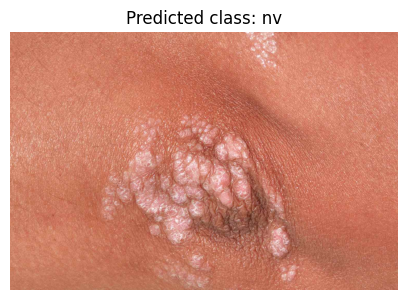

Predicted class: nv
Model confidence for predicted class: 74.56%

Class probabilities:
nv: 74.56%
bkl: 12.90%
akiec: 6.87%
mel: 4.38%
df: 0.91%
vasc: 0.35%
bcc: 0.03%


In [51]:
# Google Colab upload cell
from google.colab import files as colab_files
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

uploaded = colab_files.upload()

if not uploaded:
    print("No image uploaded.")
else:
    image_path = next(iter(uploaded.keys()))

    image = Image.open(image_path).convert("RGB")
    resized_image = image.resize((IMG_SIZE, IMG_SIZE))

    image_array = np.asarray(resized_image, dtype=np.float32)
    image_batch = np.expand_dims(image_array, axis=0)

    prediction_probabilities = best_model.predict(image_batch, verbose=0)[0]
    predicted_index = int(np.argmax(prediction_probabilities))
    predicted_class = class_names[predicted_index]

    plt.figure(figsize=(5, 5))
    plt.imshow(image)
    plt.axis("off")
    plt.title(f"Predicted class: {predicted_class}")
    plt.show()

    print("Predicted class:", predicted_class)
    print(f"Model confidence for predicted class: {prediction_probabilities[predicted_index] * 100:.2f}%")
    print("\nClass probabilities:")
    for class_name, probability in sorted(
        zip(class_names, prediction_probabilities),
        key=lambda item: item[1],
        reverse=True
    ):
        print(f"{class_name}: {probability * 100:.2f}%")


Step 23: Save the final model

In [52]:
FINAL_MODEL_PATH = "skin_lesion_classification_final.keras"
best_model.save(FINAL_MODEL_PATH)

print("Final model saved to:", FINAL_MODEL_PATH)
print("Class mapping:", class_to_index)

Final model saved to: skin_lesion_classification_final.keras
Class mapping: {'akiec': 0, 'bcc': 1, 'bkl': 2, 'df': 3, 'mel': 4, 'nv': 5, 'vasc': 6}


Important limitation
This project is for educational and research use. The model's predictions and confidence scores are not proof of a diagnosis, and the model should not be used to make clinical decisions.

In [53]:
from google.colab import files

files.download("skin_lesion_classification_final.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>